# Data Collection

In [1]:
import pandas as pd
import requests
from bs4 import BeautifulSoup

In [2]:
# Step 1: Check the Cars24 website response
import requests

url = "https://www.cars24.com/"

response = requests.get(url, timeout=20)

print("Status Code:", response.status_code)

Status Code: 200


In [3]:
# Step 2: Check the webpage HTML
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title)

<title>Cars24: Buy and sell used cars, get car loans, and check new car details with Cars24. Explore services like challan payment, car scrapping, and more.</title>


In [4]:
# Step 3: Check whether car listings are present in the HTML
print("Page length:", len(response.text))
print("Contains 'used cars':", "used cars" in response.text.lower())
print("Contains '₹':", "₹" in response.text)

Page length: 788535
Contains 'used cars': True
Contains '₹': True


In [5]:
# Step 4: Find car-related links
for link in soup.find_all("a", href=True):
    text = link.get_text(" ", strip=True)
    href = link["href"]

    if "car" in text.lower() or "car" in href.lower():
        print("Text:", text[:80])
        print("Link:", href)
        print("-" * 50)

Text: 
Link: https://www.cars24.com/
--------------------------------------------------
Text: Buy used car
Link: https://www.cars24.com/buy-used-car/
--------------------------------------------------
Text: Sell car
Link: https://www.cars24.com/sell-used-cars/
--------------------------------------------------
Text: Loans
Link: https://www.cars24.com/loans/
--------------------------------------------------
Text: Challan
Link: https://www.cars24.com/vehicle-challan/
--------------------------------------------------
Text: Car check
Link: https://www.cars24.com/car-check/
--------------------------------------------------
Text: Insurance
Link: https://www.cars24.com/vehicle-insurance/
--------------------------------------------------
Text: Home
Link: https://www.cars24.com/
--------------------------------------------------
Text: Buy used car
Link: https://www.cars24.com/buy-used-car/
--------------------------------------------------
Text: Sell car
Link: https://www.cars24.com/sell-us

In [6]:
# Step 5: Find links containing “buy”
for link in soup.find_all("a", href=True):
    text = link.get_text(" ", strip=True)
    href = link["href"]

    if "buy" in text.lower() or "buy" in href.lower():
        print("Text:", text)
        print("Link:", href)
        print("-" * 40)

Text: Buy used car
Link: https://www.cars24.com/buy-used-car/
----------------------------------------
Text: Buy used car
Link: https://www.cars24.com/buy-used-car/
----------------------------------------
Text: All used cars
Link: https://www.cars24.com/buy-used-car/
----------------------------------------
Text: Budget used cars
Link: https://www.cars24.com/buy-used-car/?f=listingPrice%3Abw%3A100000%2C700000
----------------------------------------
Text: Premium used cars New
Link: https://www.cars24.com/buy-used-car/?f=listingPrice%3Abw%3A1500000%2C5000000
----------------------------------------
Text: Get assured buyback
Link: https://cars24.com/assured-buyback/
----------------------------------------
Text: 
Link: https://apps.apple.com/in/app/cars24-sell-buy-used-cars/id1364492085
----------------------------------------
Text: 
Link: https://apps.apple.com/in/app/cars24-sell-buy-used-cars/id1364492085
----------------------------------------
Text: Buy a used car
Link: https://www

In [7]:
# Step 6: Open the used-car listings page
url = "https://www.cars24.com/buy-used-car/"

response = requests.get(url, timeout=20)

print("Status Code:", response.status_code)
print("Page Length:", len(response.text))

Status Code: 200
Page Length: 1736486


In [8]:
# Step 7
soup = BeautifulSoup(response.text, "html.parser")

print(soup.get_text(" ", strip=True)[:2000])

Buy Used Cars - Second Hand Cars In India | Cars24.com Is Hyderabad your location? Find the best cars near you Change location Continue India Buy used car Buy Used Cars in India Change city Browse by City Browse by City Used Cars in Delhi NCR Used Cars in Bangalore Used Cars in New Delhi Used Cars in Mumbai Used Cars in Hyderabad Used Cars in Pune Used Cars in Ahmedabad Used Cars in Gurgaon Used Cars in Chennai Used Cars in Noida Used Cars in Lucknow Used Cars in Ghaziabad Used Cars in Kolkata Used Cars in Jaipur Used Cars in Surat Buy cars online Sell car Sell car Used car valuation Sell car in Delhi Sell car in Mumbai Sell car in Bangalore Sell car in Hyderabad Sell car in Ahmedabad Sell car in Gurgaon Sell car in Chennai Sell car in Pune Sell car in Noida Sell car in Ghaziabad Sell car in Lucknow Sell car in Jaipur Sell car in Kolkata Sell car in Kochi Sell car in Indore Car finance Used car loan Loan against car Personal loan Credit cards Used car loan Overview Features & Benefits 

In [9]:
# Step 8
import json

scripts = soup.find_all("script", type="application/ld+json")

print("Structured data blocks found:", len(scripts))

for script in scripts[:5]:
    print(script.get_text()[:500])
    print("-" * 40)

Structured data blocks found: 4
[{"@context":"https://schema.org/","@id":"https://www.cars24.com/","url":"https://www.cars24.com/","name":"Cars24","@type":"WebPage"},{"@context":"https://schema.org/","@id":"https://www.cars24.com/","url":"https://www.cars24.com/","name":"Cars24","@type":"Website"}]
----------------------------------------
{"@context":"http://schema.org","@type":"BreadcrumbList","itemListElement":[{"@type":"ListItem","position":1,"item":{"@id":"https://www.cars24.com/","name":"Home"}},{"@type":"ListItem","position":2,"item":{"name":"Used Cars"}}]}
----------------------------------------
{"@context":"https://schema.org/","@graph":[{"@type":"ListItem","name":"2022 Renault TRIBER RXZ AMT","position":1,"url":"https://www.cars24.com/buy-used-renault-triber-2022-cars-kochi-18021977108/","description":"Buy Used Renault TRIBER, 1st owner, Petrol MRL Certified Car with up to 12-Month warranty plans","image":"https://media.cars24.com/https://media.cars24.com/hello-ar/dev/transfo

In [10]:
# Step 9:Extract car listings
import json

car_listings = []

for script in scripts:
    try:
        data = json.loads(script.get_text())

        if isinstance(data, dict):
            items = data.get("@graph", [])

            for item in items:
                if item.get("@type") == "ListItem" and item.get("url"):
                    car_listings.append({
                        "car_name": item.get("name"),
                        "description": item.get("description"),
                        "listing_url": item.get("url"),
                        "image_url": item.get("image")
                    })

    except json.JSONDecodeError:
        continue

cars_df = pd.DataFrame(car_listings)

print("Total listings found:", len(cars_df))
display(cars_df.head())

Total listings found: 20


,car_name,description,listing_url,image_url
0,2022 Renault TRIBER RXZ AMT,"Buy Used Renault TRIBER, 1st owner, Petrol MRL...",https://www.cars24.com/buy-used-renault-triber...,https://media.cars24.com/https://media.cars24....
1,2018 Honda City 1.5L I-VTEC VX CVT,"Buy Used Honda City, 1st owner, Petrol MRL Cer...",https://www.cars24.com/buy-used-honda-city-201...,https://media.cars24.com/https://media.cars24....
2,2021 Hyundai NEW I20 N LINE N8 1.0 TURBO GDI DCT,"Buy Used Hyundai NEW I20 N LINE, 1st owner, Pe...",https://www.cars24.com/buy-used-hyundai-new-i2...,https://media.cars24.com/https://media.cars24....
3,2019 Maruti Dzire VXI,"Buy Used Maruti Dzire, 1st owner, Petrol MRL C...",https://www.cars24.com/buy-used-maruti-dzire-2...,https://media.cars24.com/https://media.cars24....
4,2024 Honda Amaze 1.2L I-VTEC VX,"Buy Used Honda Amaze, 1st owner, Petrol MRL Ce...",https://www.cars24.com/buy-used-honda-amaze-20...,https://media.cars24.com/https://media.cars24....


In [11]:
# Step 10:Check the collected data
print("Total records:", len(cars_df))
print("\nMissing values:")
print(cars_df.isnull().sum())

print("\nDuplicate listing URLs:")
print(cars_df["listing_url"].duplicated().sum())

print("\nCar names:")
display(cars_df[["car_name", "listing_url"]])

Total records: 20

Missing values:
car_name       0
description    0
listing_url    0
image_url      0
dtype: int64

Duplicate listing URLs:
0

Car names:


,car_name,listing_url
0,2022 Renault TRIBER RXZ AMT,https://www.cars24.com/buy-used-renault-triber...
1,2018 Honda City 1.5L I-VTEC VX CVT,https://www.cars24.com/buy-used-honda-city-201...
2,2021 Hyundai NEW I20 N LINE N8 1.0 TURBO GDI DCT,https://www.cars24.com/buy-used-hyundai-new-i2...
3,2019 Maruti Dzire VXI,https://www.cars24.com/buy-used-maruti-dzire-2...
4,2024 Honda Amaze 1.2L I-VTEC VX,https://www.cars24.com/buy-used-honda-amaze-20...
5,2015 Hyundai Creta S 1.6 PETROL,https://www.cars24.com/buy-used-hyundai-creta-...
6,2021 MG HECTOR PLUS SHARP 1.5 PETROL TURBO DCT...,https://www.cars24.com/buy-used-mg-hector-plus...
7,2021 Hyundai NEW I20 SPORTZ 1.2 AT,https://www.cars24.com/buy-used-hyundai-new-i2...
8,2023 KIA SELTOS HTK 1.5 DIESEL IMT,https://www.cars24.com/buy-used-kia-seltos-202...
9,2020 KIA SONET GTX PLUS 1.0 DCT DUAL TONE,https://www.cars24.com/buy-used-kia-sonet-2020...


In [12]:
# Step 11:Extract car details
test_url = cars_df.loc[0, "listing_url"]

car_response = requests.get(test_url, timeout=20)

print("Status Code:", car_response.status_code)
print("Page Length:", len(car_response.text))

Status Code: 200
Page Length: 1132906


In [13]:
# Step 12:Inspect the car listing's structured data
car_soup = BeautifulSoup(car_response.text, "html.parser")

car_scripts = car_soup.find_all(
    "script",
    type="application/ld+json"
)

print("Structured data blocks:", len(car_scripts))

for script in car_scripts:
    print(script.get_text()[:1000])
    print("-" * 50)

Structured data blocks: 3
[{"@context":"https://schema.org/","@id":"https://www.cars24.com/","url":"https://www.cars24.com/","name":"Cars24","@type":"WebPage"},{"@context":"https://schema.org/","@id":"https://www.cars24.com/","url":"https://www.cars24.com/","name":"Cars24","@type":"Website"}]
--------------------------------------------------
{"@context":"http://schema.org","@type":"BreadcrumbList","itemListElement":[{"@type":"ListItem","position":1,"item":{"@id":"https://www.cars24.com/","name":"Home"}},{"@type":"ListItem","position":2,"item":{"@id":"https://www.cars24.com/buy-used-cars/","name":"Used Cars"}},{"@type":"ListItem","position":3,"item":{"@id":"https://www.cars24.com/buy-used-cars-kochi/","name":"Used Cars in Kochi"}},{"@type":"ListItem","position":4,"item":{"@id":"https://www.cars24.com/buy-used-renault-cars-kochi/","name":"Used Renault Cars in Kochi"}},{"@type":"ListItem","position":5,"item":{"@id":"https://www.cars24.com/buy-used-renault-triber-cars-kochi/","name":"Used

In [14]:
# Step 13:Collect details from all 20 listings

import json

def extract_car_details(listing_url):
    try:
        page = requests.get(listing_url, timeout=20)
        page_soup = BeautifulSoup(page.text, "html.parser")

        for script in page_soup.find_all(
            "script", type="application/ld+json"
        ):
            try:
                data = json.loads(script.get_text())

                if isinstance(data, dict) and data.get("@type") == "Car":
                    offers = data.get("offers", {})
                    mileage = data.get("mileageFromOdometer", {})

                    breadcrumbs = [
                        s.get_text(" ", strip=True)
                        for s in page_soup.select(
                            'script[type="application/ld+json"]'
                        )
                    ]

                    return {
                        "brand": data.get("brand", {}).get("name"),
                        "model": data.get("model"),
                        "year": data.get("vehicleModelDate"),
                        "body_type": data.get("bodyType"),
                        "fuel_type": data.get("fuelType"),
                        "transmission": data.get("vehicleTransmission"),
                        "price": offers.get("price"),
                        "mileage_km": mileage.get("value"),
                        "availability": offers.get("availability")
                    }

            except (json.JSONDecodeError, AttributeError):
                continue

    except requests.RequestException:
        pass

    return {}

In [15]:
# Step 14:Test the function on one car
car_details = extract_car_details(cars_df.loc[0, "listing_url"])

print(car_details)

{'brand': 'Renault', 'model': 'TRIBER', 'year': 2022, 'body_type': 'SUV', 'fuel_type': 'Petrol', 'transmission': 'Automatic', 'price': 620711, 'mileage_km': 34579, 'availability': 'https://schema.org/InStock'}


In [16]:
# Step 15:Collect details for all 20 cars

car_details_list = []

for url in cars_df["listing_url"]:
    details = extract_car_details(url)
    car_details_list.append(details)

details_df = pd.DataFrame(car_details_list)

# Combine the original car information with the extracted details
cars_df = pd.concat(
    [cars_df.reset_index(drop=True), details_df],
    axis=1
)

print("Total records:", len(cars_df))
display(cars_df.head())

Total records: 20


,car_name,description,listing_url,image_url,brand,model,year,body_type,fuel_type,transmission,price,mileage_km,availability
0,2022 Renault TRIBER RXZ AMT,"Buy Used Renault TRIBER, 1st owner, Petrol MRL...",https://www.cars24.com/buy-used-renault-triber...,https://media.cars24.com/https://media.cars24....,Renault,TRIBER,2022,SUV,Petrol,Automatic,620711,34579,https://schema.org/InStock
1,2018 Honda City 1.5L I-VTEC VX CVT,"Buy Used Honda City, 1st owner, Petrol MRL Cer...",https://www.cars24.com/buy-used-honda-city-201...,https://media.cars24.com/https://media.cars24....,Honda,City,2018,Sedan,Petrol,Automatic,708920,22011,https://schema.org/InStock
2,2021 Hyundai NEW I20 N LINE N8 1.0 TURBO GDI DCT,"Buy Used Hyundai NEW I20 N LINE, 1st owner, Pe...",https://www.cars24.com/buy-used-hyundai-new-i2...,https://media.cars24.com/https://media.cars24....,Hyundai,NEW I20 N LINE,2021,Hatchback,Petrol,Automatic,758474,30278,https://schema.org/InStock
3,2019 Maruti Dzire VXI,"Buy Used Maruti Dzire, 1st owner, Petrol MRL C...",https://www.cars24.com/buy-used-maruti-dzire-2...,https://media.cars24.com/https://media.cars24....,Maruti,Dzire,2019,Sedan,Petrol,Manual,509399,19349,https://schema.org/InStock
4,2024 Honda Amaze 1.2L I-VTEC VX,"Buy Used Honda Amaze, 1st owner, Petrol MRL Ce...",https://www.cars24.com/buy-used-honda-amaze-20...,https://media.cars24.com/https://media.cars24....,Honda,Amaze,2024,Sedan,Petrol,Manual,689558,11070,https://schema.org/InStock


In [17]:
# Step 16:Verify the full dataset
print("Dataset shape:", cars_df.shape)
print("\nColumn names:")
print(cars_df.columns.tolist())

display(cars_df)

Dataset shape: (20, 13)

Column names:
['car_name', 'description', 'listing_url', 'image_url', 'brand', 'model', 'year', 'body_type', 'fuel_type', 'transmission', 'price', 'mileage_km', 'availability']


,car_name,description,listing_url,image_url,brand,model,year,body_type,fuel_type,transmission,price,mileage_km,availability
0,2022 Renault TRIBER RXZ AMT,"Buy Used Renault TRIBER, 1st owner, Petrol MRL...",https://www.cars24.com/buy-used-renault-triber...,https://media.cars24.com/https://media.cars24....,Renault,TRIBER,2022,SUV,Petrol,Automatic,620711,34579,https://schema.org/InStock
1,2018 Honda City 1.5L I-VTEC VX CVT,"Buy Used Honda City, 1st owner, Petrol MRL Cer...",https://www.cars24.com/buy-used-honda-city-201...,https://media.cars24.com/https://media.cars24....,Honda,City,2018,Sedan,Petrol,Automatic,708920,22011,https://schema.org/InStock
2,2021 Hyundai NEW I20 N LINE N8 1.0 TURBO GDI DCT,"Buy Used Hyundai NEW I20 N LINE, 1st owner, Pe...",https://www.cars24.com/buy-used-hyundai-new-i2...,https://media.cars24.com/https://media.cars24....,Hyundai,NEW I20 N LINE,2021,Hatchback,Petrol,Automatic,758474,30278,https://schema.org/InStock
3,2019 Maruti Dzire VXI,"Buy Used Maruti Dzire, 1st owner, Petrol MRL C...",https://www.cars24.com/buy-used-maruti-dzire-2...,https://media.cars24.com/https://media.cars24....,Maruti,Dzire,2019,Sedan,Petrol,Manual,509399,19349,https://schema.org/InStock
4,2024 Honda Amaze 1.2L I-VTEC VX,"Buy Used Honda Amaze, 1st owner, Petrol MRL Ce...",https://www.cars24.com/buy-used-honda-amaze-20...,https://media.cars24.com/https://media.cars24....,Honda,Amaze,2024,Sedan,Petrol,Manual,689558,11070,https://schema.org/InStock
5,2015 Hyundai Creta S 1.6 PETROL,"Buy Used Hyundai Creta, 1st owner, Petrol MRL ...",https://www.cars24.com/buy-used-hyundai-creta-...,https://media.cars24.com/https://media.cars24....,Hyundai,Creta,2015,SUV,Petrol,Manual,514634,68857,https://schema.org/InStock
6,2021 MG HECTOR PLUS SHARP 1.5 PETROL TURBO DCT...,"Buy Used MG HECTOR PLUS, 2nd owner, CNG MRL Ce...",https://www.cars24.com/buy-used-mg-hector-plus...,https://media.cars24.com/https://media.cars24....,MG,HECTOR PLUS,2021,SUV,CNG,Automatic,1088682,67734,https://schema.org/InStock
7,2021 Hyundai NEW I20 SPORTZ 1.2 AT,"Buy Used Hyundai NEW I20, 1st owner, Petrol MR...",https://www.cars24.com/buy-used-hyundai-new-i2...,https://media.cars24.com/https://media.cars24....,Hyundai,NEW I20,2021,Hatchback,Petrol,Automatic,607526,52971,https://schema.org/InStock
8,2023 KIA SELTOS HTK 1.5 DIESEL IMT,"Buy Used KIA SELTOS, 1st owner, Diesel MRL Cer...",https://www.cars24.com/buy-used-kia-seltos-202...,https://media.cars24.com/https://media.cars24....,KIA,SELTOS,2023,SUV,Diesel,Manual,989020,86039,https://schema.org/InStock
9,2020 KIA SONET GTX PLUS 1.0 DCT DUAL TONE,"Buy Used KIA SONET, 1st owner, Petrol MRL Cert...",https://www.cars24.com/buy-used-kia-sonet-2020...,https://media.cars24.com/https://media.cars24....,KIA,SONET,2020,SUV,Petrol,Automatic,781750,65337,https://schema.org/InStock


In [21]:
# Step 17:Check the location of all 20 cars
import json

def extract_car_location(listing_url):
    try:
        response = requests.get(listing_url, timeout=20)
        page_soup = BeautifulSoup(response.text, "html.parser")

        for script in page_soup.find_all(
            "script", type="application/ld+json"
        ):
            try:
                data = json.loads(script.get_text())

                if data.get("@type") == "BreadcrumbList":
                    items = data.get("itemListElement", [])
                    for item in items:
                        name = item.get("item", {}).get("name", "")
                        if name.startswith("Used Cars in "):
                            return name.replace("Used Cars in ", "")

            except (json.JSONDecodeError, AttributeError):
                continue

    except requests.RequestException:
        pass

    return "Not found"


cars_df["location"] = cars_df["listing_url"].apply(
    extract_car_location
)

print(cars_df["location"].value_counts(dropna=False))
display(cars_df[["car_name", "location"]])

location
Delhi NCR     3
Pune          2
Patna         2
Hyderabad     2
Bangalore     2
Kochi         1
Indore        1
Rajkot        1
Dehradun      1
Ludhiana      1
Kolkata       1
Jaipur        1
Mumbai        1
Coimbatore    1
Name: count, dtype: int64


,car_name,location
0,2022 Renault TRIBER RXZ AMT,Kochi
1,2018 Honda City 1.5L I-VTEC VX CVT,Pune
2,2021 Hyundai NEW I20 N LINE N8 1.0 TURBO GDI DCT,Patna
3,2019 Maruti Dzire VXI,Indore
4,2024 Honda Amaze 1.2L I-VTEC VX,Rajkot
5,2015 Hyundai Creta S 1.6 PETROL,Patna
6,2021 MG HECTOR PLUS SHARP 1.5 PETROL TURBO DCT...,Delhi NCR
7,2021 Hyundai NEW I20 SPORTZ 1.2 AT,Dehradun
8,2023 KIA SELTOS HTK 1.5 DIESEL IMT,Ludhiana
9,2020 KIA SONET GTX PLUS 1.0 DCT DUAL TONE,Hyderabad


In [22]:
# Step 18:Final check for Data Collection
required_columns = [
    "car_name", "brand", "model", "year",
    "body_type", "fuel_type", "transmission",
    "price", "mileage_km", "location"
]

print("Total records:", len(cars_df))
print("\nMissing required values:")
print(cars_df[required_columns].isnull().sum())

print("\nNumber of unique listing URLs:",
      cars_df["listing_url"].nunique())

print("\nCities covered:", cars_df["location"].nunique())

Total records: 20

Missing required values:
car_name        0
brand           0
model           0
year            0
body_type       0
fuel_type       0
transmission    0
price           0
mileage_km      0
location        0
dtype: int64

Number of unique listing URLs: 20

Cities covered: 14


# Data Understanding

In [23]:
# Step 1: Understand the dataset structure

cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   car_name      20 non-null     object
 1   description   20 non-null     object
 2   listing_url   20 non-null     object
 3   image_url     20 non-null     object
 4   brand         20 non-null     object
 5   model         20 non-null     object
 6   year          20 non-null     int64 
 7   body_type     20 non-null     object
 8   fuel_type     20 non-null     object
 9   transmission  20 non-null     object
 10  price         20 non-null     int64 
 11  mileage_km    20 non-null     int64 
 12  availability  20 non-null     object
 13  location      20 non-null     object
dtypes: int64(3), object(11)
memory usage: 2.3+ KB


In [24]:
# Step 2: Understand numerical data
cars_df.describe()

,year,price,mileage_km
count,20.000000,2.000000e+01,20.00000
mean,2020.750000,7.671656e+05,47729.70000
std,2.672964,3.457348e+05,24712.50087
min,2015.000000,2.796250e+05,4482.00000
25%,2019.000000,5.133252e+05,29666.25000
50%,2021.000000,7.336970e+05,45887.50000
75%,2023.000000,9.217118e+05,68014.75000
max,2025.000000,1.622028e+06,86039.00000


In [25]:
# Step 3:Understand categorical data
print("Fuel Types:")
print(cars_df["fuel_type"].value_counts())

print("\nTransmission Types:")
print(cars_df["transmission"].value_counts())

print("\nBody Types:")
print(cars_df["body_type"].value_counts())

print("\nCar Locations:")
print(cars_df["location"].value_counts())

Fuel Types:
fuel_type
Petrol    17
Diesel     2
CNG        1
Name: count, dtype: int64

Transmission Types:
transmission
Automatic    10
Manual       10
Name: count, dtype: int64

Body Types:
body_type
SUV          11
Hatchback     6
Sedan         3
Name: count, dtype: int64

Car Locations:
location
Delhi NCR     3
Pune          2
Patna         2
Hyderabad     2
Bangalore     2
Kochi         1
Indore        1
Rajkot        1
Dehradun      1
Ludhiana      1
Kolkata       1
Jaipur        1
Mumbai        1
Coimbatore    1
Name: count, dtype: int64


In [28]:
# Step 4:Unique Value Analysis
print("Unique brands:", cars_df["brand"].nunique())
print("Unique models:", cars_df["model"].nunique())
print("Unique years:", cars_df["year"].nunique())
print("Unique prices:", cars_df["price"].nunique())
print("Unique mileage values:", cars_df["mileage_km"].nunique())

Unique brands: 10
Unique models: 16
Unique years: 10
Unique prices: 20
Unique mileage values: 20


In [29]:
# Step 5:Data Validity Check
print("Year range:", cars_df["year"].min(), "-", cars_df["year"].max())
print("Price range:", cars_df["price"].min(), "-", cars_df["price"].max())
print("Mileage range:", cars_df["mileage_km"].min(), "-", cars_df["mileage_km"].max())

print("Invalid years:", ((cars_df["year"] < 1900) | (cars_df["year"] > 2026)).sum())
print("Zero or negative prices:", (cars_df["price"] <= 0).sum())
print("Negative mileage:", (cars_df["mileage_km"] < 0).sum())

Year range: 2015 - 2025
Price range: 279625 - 1622028
Mileage range: 4482 - 86039
Invalid years: 0
Zero or negative prices: 0
Negative mileage: 0


# Data Cleaning

In [30]:
# step 1: Duplicate Records Check
cars_df.duplicated().sum()

np.int64(0)

In [31]:
# step 2: Missing Values Check
cars_df.isnull().sum()

car_name        0
description     0
listing_url     0
image_url       0
brand           0
model           0
year            0
body_type       0
fuel_type       0
transmission    0
price           0
mileage_km      0
availability    0
location        0
dtype: int64

In [32]:
# step 3: Check Duplicate Listing URLs
cars_df["listing_url"].duplicated().sum()

np.int64(0)

In [33]:
# Step 4: Data Validation
cars_df.dtypes

car_name        object
description     object
listing_url     object
image_url       object
brand           object
model           object
year             int64
body_type       object
fuel_type       object
transmission    object
price            int64
mileage_km       int64
availability    object
location        object
dtype: object

# Exploratory Data Analysis

In [44]:
# Step 1:Analyze numerical columns
cars_df[["year", "price", "mileage_km"]].describe()

,year,price,mileage_km
count,20.000000,2.000000e+01,20.00000
mean,2020.750000,7.671656e+05,47729.70000
std,2.672964,3.457348e+05,24712.50087
min,2015.000000,2.796250e+05,4482.00000
25%,2019.000000,5.133252e+05,29666.25000
50%,2021.000000,7.336970e+05,45887.50000
75%,2023.000000,9.217118e+05,68014.75000
max,2025.000000,1.622028e+06,86039.00000


In [45]:
# Step 2:Analyze categorical columns
print("Fuel Type Distribution:")
print(cars_df["fuel_type"].value_counts())

print("\nBody Type Distribution:")
print(cars_df["body_type"].value_counts())

print("\nTransmission Distribution:")
print(cars_df["transmission"].value_counts())

print("\nCar Listings by Location:")
print(cars_df["location"].value_counts())

Fuel Type Distribution:
fuel_type
Petrol    17
Diesel     2
CNG        1
Name: count, dtype: int64

Body Type Distribution:
body_type
SUV          11
Hatchback     6
Sedan         3
Name: count, dtype: int64

Transmission Distribution:
transmission
Automatic    10
Manual       10
Name: count, dtype: int64

Car Listings by Location:
location
Delhi NCR     3
Pune          2
Patna         2
Hyderabad     2
Bangalore     2
Kochi         1
Indore        1
Rajkot        1
Dehradun      1
Ludhiana      1
Kolkata       1
Jaipur        1
Mumbai        1
Coimbatore    1
Name: count, dtype: int64


In [46]:
# Step 3:Check unique values
cars_df[["brand", "model", "year", "fuel_type", "body_type"]].nunique()

brand        10
model        16
year         10
fuel_type     3
body_type     3
dtype: int64

In [47]:
# Step 4: Correlation analysis
cars_df[["year", "price", "mileage_km"]].corr()

,year,price,mileage_km
year,1.000000,0.524630,-0.340164
price,0.524630,1.000000,0.085596
mileage_km,-0.340164,0.085596,1.000000


In [ ]:
# Step 5:EDA observations
Price Analysis:
The average car price is approximately ₹7.67 lakh, with prices ranging from ₹2.80 lakh to ₹16.22 lakh.
Year Analysis:
The model years range from 2015 to 2025, showing that the dataset includes both older and newer cars.
Fuel Type Analysis:
Petrol cars account for 17 out of 20 listings, making petrol the most common fuel type in this sample.
Body Type Analysis:
SUVs are the most common body type, with 11 listings, followed by hatchbacks with 6 and sedans with 3.
Transmission Analysis:
Automatic and manual cars are equally represented, with 10 listings each.
Mileage Analysis:
Mileage ranges from 4,482 km to 86,039 km, indicating considerable variation among the collected cars.
Relationship Analysis: 
Car prices vary across model years and mileage levels. Other factors, including brand, model, and vehicle condition, may also influence prices.

# Data Visualizations

In [34]:
# Step 1: Analyze Car Price Distribution
cars_df["price"].describe()

count    2.000000e+01
mean     7.671656e+05
std      3.457348e+05
min      2.796250e+05
25%      5.133252e+05
50%      7.336970e+05
75%      9.217118e+05
max      1.622028e+06
Name: price, dtype: float64

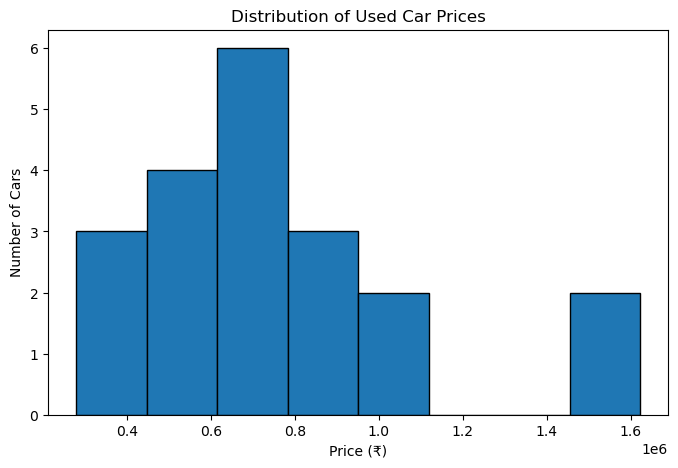

In [35]:
# Step 2: Visualize Car Price Distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(cars_df["price"], bins=8, edgecolor="black")
plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Cars")
plt.show()

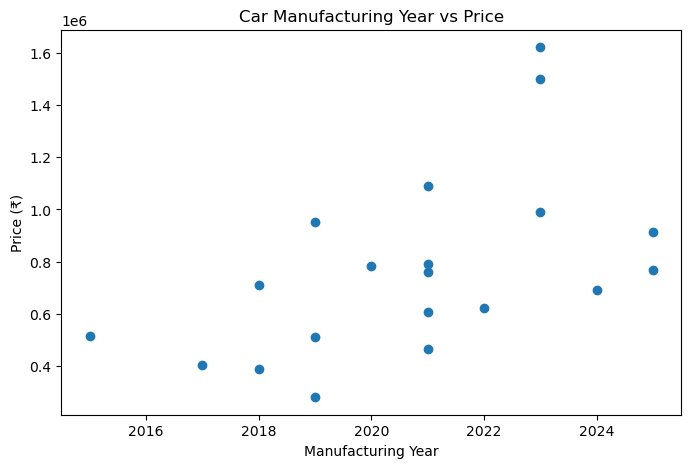

In [36]:
# Step 3: Price Analysis by Manufacturing Year
plt.figure(figsize=(8, 5))
plt.scatter(cars_df["year"], cars_df["price"])
plt.title("Car Manufacturing Year vs Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Price (₹)")
plt.show()

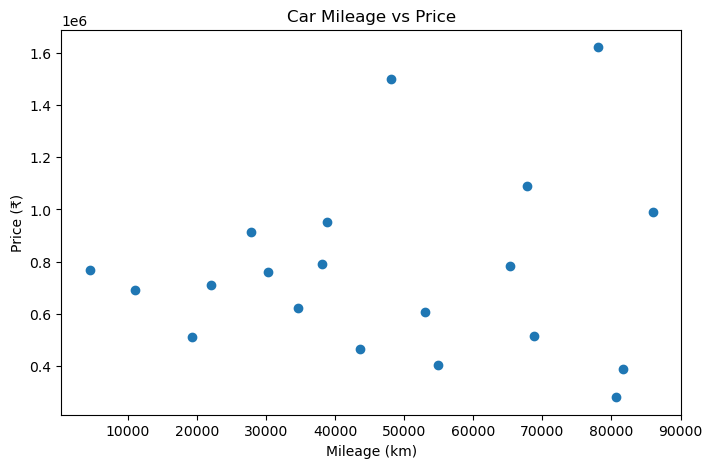

In [37]:
# Step 4: Mileage vs. Price Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(cars_df["mileage_km"], cars_df["price"])
plt.title("Car Mileage vs Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (₹)")
plt.show()

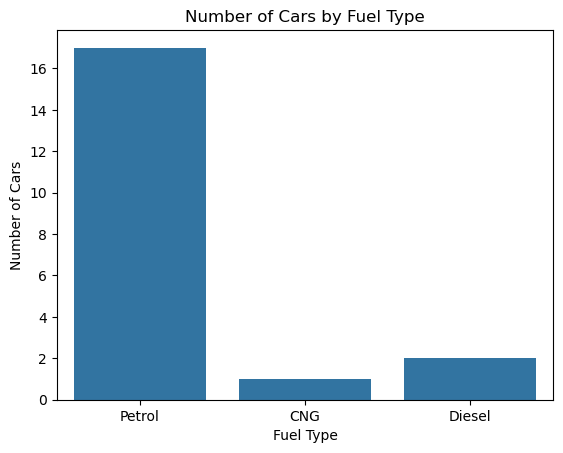

In [39]:
# Step 5:Fuel Type Analysis
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=cars_df, x="fuel_type")

plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.show()

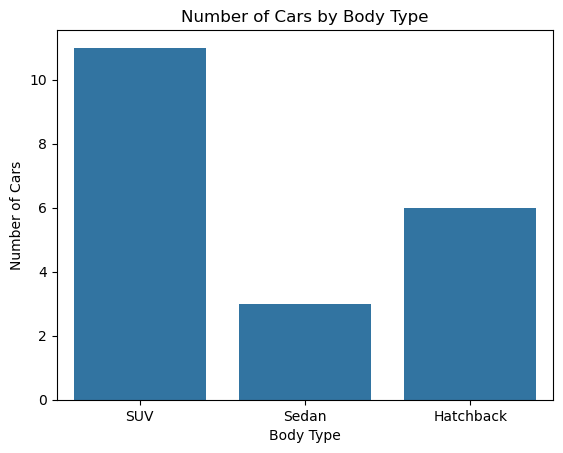

In [40]:
# Step 5: Body Type Analysis
sns.countplot(data=cars_df, x="body_type")

plt.title("Number of Cars by Body Type")
plt.xlabel("Body Type")
plt.ylabel("Number of Cars")
plt.show()

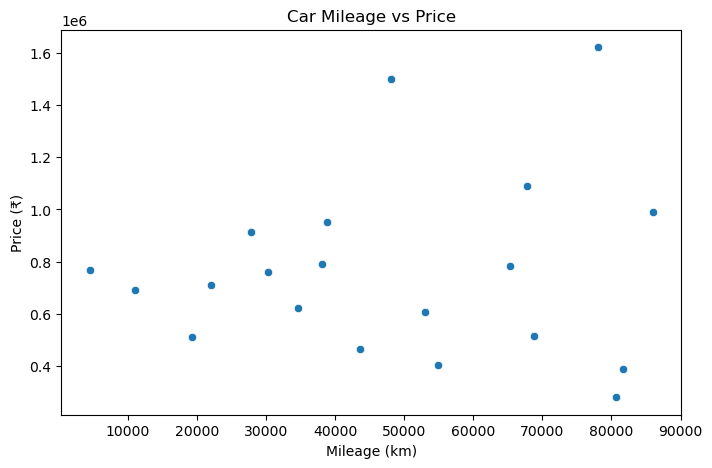

In [41]:
# Step 6: Mileage vs. Price Analysis
plt.figure(figsize=(8, 5))

sns.scatterplot(data=cars_df, x="mileage_km", y="price")

plt.title("Car Mileage vs Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (₹)")
plt.show()

# Data Validation

In [42]:
# Step 1: Check your visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

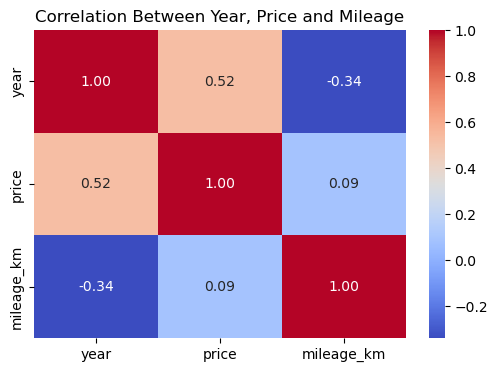

In [43]:
# Step 2:Correlation Analysis
numeric_cols = ["year", "price", "mileage_km"]

correlation = cars_df[numeric_cols].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Year, Price and Mileage")
plt.show()

# Business Insights & Recommendations

In [48]:
# Step 1: Key business metrics
print("Average Price:", round(cars_df["price"].mean(), 2))
print("Median Price:", round(cars_df["price"].median(), 2))
print("Average Mileage:", round(cars_df["mileage_km"].mean(), 2))
print("Total Listings:", len(cars_df))

Average Price: 767165.6
Median Price: 733697.0
Average Mileage: 47729.7
Total Listings: 20


In [49]:
# Step 2: Compare average price by fuel type
cars_df.groupby("fuel_type")["price"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
fuel_type,,,
CNG,1,1088682.00,1088682.0
Diesel,2,1245009.50,1245009.5
Petrol,17,692035.94,689558.0


In [50]:
# Step 3: Compare average price by body type
cars_df.groupby("body_type")["price"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
body_type,,,
Hatchback,6,533601.83,505266.5
SUV,11,930347.64,912017.0
Sedan,3,635959.00,689558.0


In [51]:
# Step 4: Compare price by model year
cars_df.groupby("year")["price"].mean().round(2).sort_index()

year
2015     514634.00
2017     403007.00
2018     547998.50
2019     579940.00
2020     781750.00
2021     741573.80
2022     620711.00
2023    1370682.33
2024     689558.00
2025     838959.50
Name: price, dtype: float64

# Problem Statement

In [52]:
# Step 1. Area-wise Used Car Analysis
cars_df.groupby("location")["price"].agg(
    ["count", "mean", "median"]
).round(2).sort_values("count", ascending=False)

,count,mean,median
location,,,
Delhi NCR,3,821311.0,912017.0
Bangalore,2,777927.5,777927.5
Hyderabad,2,1141374.5,1141374.5
Patna,2,636554.0,636554.0
Pune,2,829858.0,829858.0
Coimbatore,1,279625.0,279625.0
Dehradun,1,607526.0,607526.0
Indore,1,509399.0,509399.0
Jaipur,1,403007.0,403007.0


In [53]:
# Step 2:Brand-wise Used Car Analysis
cars_df.groupby("brand")["price"].agg(
    ["count", "mean", "median"]
).round(2).sort_values("mean", ascending=False)

,count,mean,median
brand,,,
Mahindra,1,1622028.00,1622028.0
MG,1,1088682.00,1088682.0
KIA,4,1055641.25,969908.0
Tata,2,850985.00,850985.0
Honda,2,699239.00,699239.0
Renault,2,693306.50,693306.5
Hyundai,5,534143.60,514634.0
Maruti,1,509399.00,509399.0
Nissan,1,463234.00,463234.0


In [54]:
# Step 3:Geographical Coverage of Collected Listings
print("Total listings:", len(cars_df))
print("Number of cities:", cars_df["location"].nunique())

print("\nListings by location:")
print(cars_df["location"].value_counts())

Total listings: 20
Number of cities: 14

Listings by location:
location
Delhi NCR     3
Pune          2
Patna         2
Hyderabad     2
Bangalore     2
Kochi         1
Indore        1
Rajkot        1
Dehradun      1
Ludhiana      1
Kolkata       1
Jaipur        1
Mumbai        1
Coimbatore    1
Name: count, dtype: int64


In [55]:
# Step 4:City-wise Price Comparison
city_analysis = cars_df.groupby("location").agg(
    total_cars=("price", "count"),
    average_price=("price", "mean"),
    median_price=("price", "median")
).round(2)

city_analysis = city_analysis.sort_values(
    "average_price", ascending=False
)

city_analysis

,total_cars,average_price,median_price
location,,,
Mumbai,1,1622028.0,1622028.0
Hyderabad,2,1141374.5,1141374.5
Ludhiana,1,989020.0,989020.0
Pune,2,829858.0,829858.0
Delhi NCR,3,821311.0,912017.0
Bangalore,2,777927.5,777927.5
Rajkot,1,689558.0,689558.0
Patna,2,636554.0,636554.0
Kochi,1,620711.0,620711.0


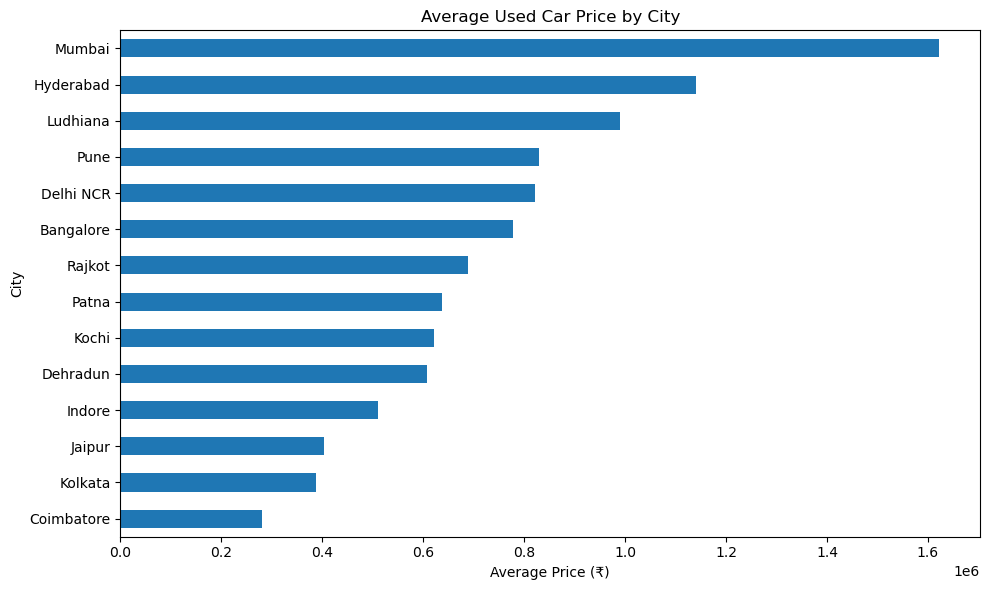

In [56]:
import matplotlib.pyplot as plt

city_analysis["average_price"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Average Used Car Price by City")
plt.xlabel("Average Price (₹)")
plt.ylabel("City")
plt.tight_layout()
plt.show()